## Reproduction of results from *Slime mould algorithm: A new method for stochastic optimization*

This notebook is meant to reproduce the results from the paper using the mealpy Slime Mould Algorithm (SMA) module. The original paper's results were produced using matlab.

In [12]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [26]:
import numpy as np
from mealpy import FloatVar, SMA, GWO, WOA, PSO
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score


### Testing Benchmark Functions:

In this section, I perform SMA on three types of functions to test the algorithm's behavior on different problems: 
1. sphere - convergence speed
2. Rastrigin - can it escape local optima?
3. Rosenbrock - test behavior in a narrow valley

I compare SMA's performance to other mealpy algorithms that the paper also used: Grey Wold Optimizer (GWO), Whale Optimization Algorithm (WOA), and Particle Swarm Optimization(PSO). I used mean, standard deviation, best, and worst across runs along with convergence curves and a Wilcoxon rank-sum test for significance, just like the paper.


### Define Functions:

In [14]:
def make_problem(lower_bound, upper_bound, minmax,objective_function, dim=30):
    return {
        'bounds': FloatVar(lb=(lower_bound,)*dim, ub=(upper_bound,)*dim),
        'minmax': minmax,
        'obj_func': objective_function,
        'log_to':None
    }

def run_models(problem,epoch=1000, pop_size=30, p_t=0.03,n_runs=30):

    algorithms = {
        'SMA': SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=p_t),
        'GWO': GWO.OriginalGWO(epoch=epoch, pop_size=pop_size),
        'WOA': WOA.OriginalWOA(epoch=epoch, pop_size=pop_size),
        'PSO': PSO.OriginalPSO(epoch=epoch, pop_size=pop_size)
    }

    final_fitness = {name: [] for name in algorithms}
    histories = {name: [] for name in algorithms}

    for name, make_model in algorithms.items():
        for run in range(n_runs):
            model = make_model
            g_best = model.solve(problem, seed=run)
            final_fitness[name].append(g_best.target.fitness)
            histories[name].append(model.history.list_global_best_fit)
        
    rows = []
    for name, vals in final_fitness.items():
        vals = np.array(vals)
        rows.append({
            "Algorithm": name,
            "AVG":vals.mean(),
            "STD":vals.std(),
            'MED':np.median(vals)
        })

    table = pd.DataFrame(rows).set_index("Algorithm")
    return table, final_fitness, histories

In [15]:
#Plot convergence curves
def plot_convergence(histories, title="Convergence Curves",save_path=None):
    fig, ax = plt.subplots(figsize=(10, 6))

    for name, history in histories.items():
        avg_history = np.mean(history, axis=0)
        ax.plot(avg_history, label=name)

    ax.set_yscale('log')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Best fitness (mean over runs)")
    ax.legend()
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if save_path:
        fig.savefig(save_path, bbox_inches='tight', dpi=300)

    plt.show()

### Function 1: Sphere (F1)

In [16]:
def sphere_objective_function(solution):
    return np.sum(solution**2)

problem = make_problem(lower_bound=-100, upper_bound=100, minmax="min", objective_function=sphere_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:168: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)


                 AVG       STD        MED
Algorithm                                
SMA        0.000e+00 0.000e+00  0.000e+00
GWO        4.591e-65 1.081e-64  8.948e-66
WOA       1.890e-183 0.000e+00 5.308e-192
PSO        8.510e+01 1.436e+02  3.794e+01


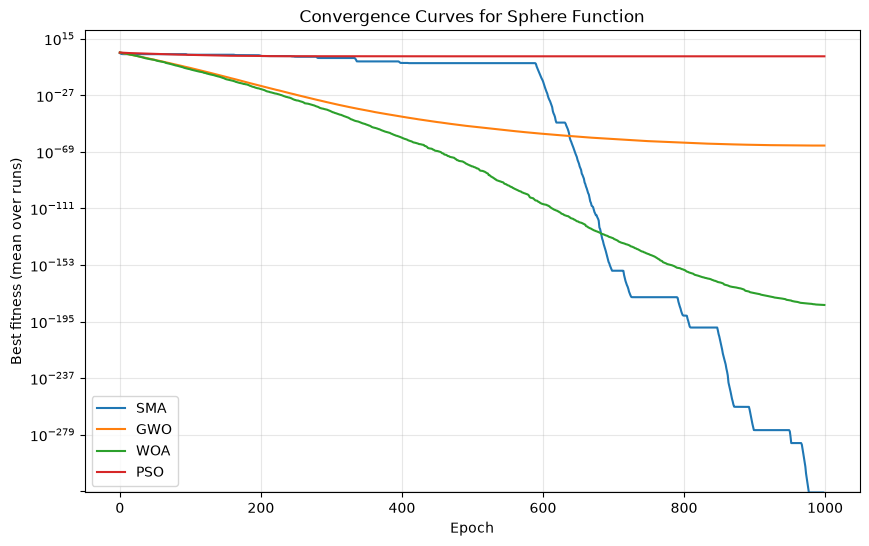

In [17]:
plot_convergence(histories, title="Convergence Curves for Sphere Function", save_path="convergence_curves.png")


## Function 2: Rastrigin (F9)

In [18]:
def rastrigin_objective_function(solution):
    return np.sum(solution**2 - 10 * np.cos(2 * np.pi * solution) + 10)

problem = make_problem(lower_bound=-5.12, upper_bound=5.12, minmax="min", objective_function=rastrigin_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

/Users/sofieappel/miniconda3/envs/mealpy-env/lib/python3.11/site-packages/mealpy/bio_based/SMA.py:168: RuntimeWarning: invalid value encountered in log10
  np.log10((self.g_best.target.fitness - self.pop[idx].target.fitness) / ss + 1)


                AVG       STD       MED
Algorithm                              
SMA       0.000e+00 0.000e+00 0.000e+00
GWO       1.291e+01 9.410e+00 1.028e+01
WOA       1.098e+02 8.568e+01 1.369e+02
PSO       8.451e+01 1.656e+01 8.312e+01


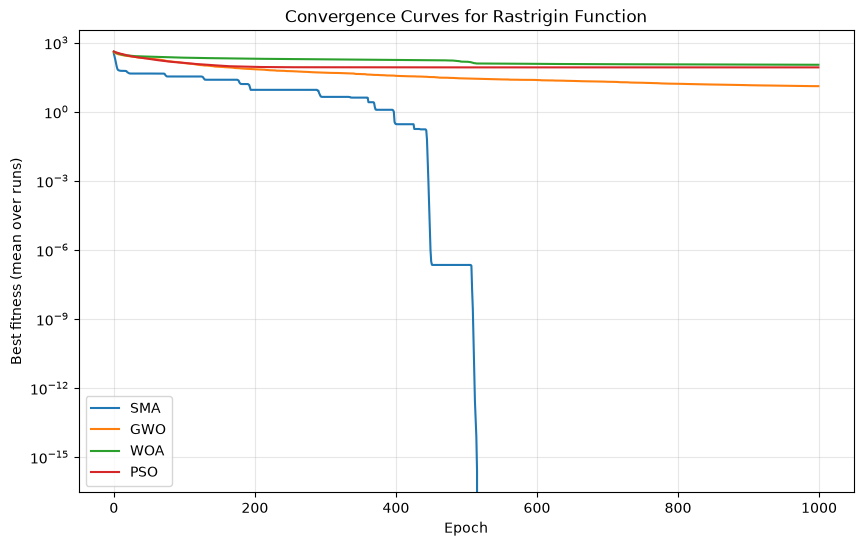

In [19]:
plot_convergence(histories, title="Convergence Curves for Rastrigin Function", save_path="convergence_curve_ragistrin.png")


## Function 3: Rosenbrock (F5)

In [20]:
def rosenbrock_objective_function(solution):
    return np.sum(100 * (solution[1:] - solution[:-1]**2)**2 + (solution[:-1] - 1)**2)

problem = make_problem(lower_bound=-30, upper_bound=30, minmax="min", objective_function=rosenbrock_objective_function, dim=30)

table, final_fitness, histories = run_models(problem, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.3e}"))

                AVG       STD       MED
Algorithm                              
SMA       2.805e+01 2.744e-01 2.811e+01
GWO       2.641e+01 8.583e-01 2.616e+01
WOA       2.732e+01 5.957e-01 2.723e+01
PSO       2.787e+03 1.000e+04 3.890e+02


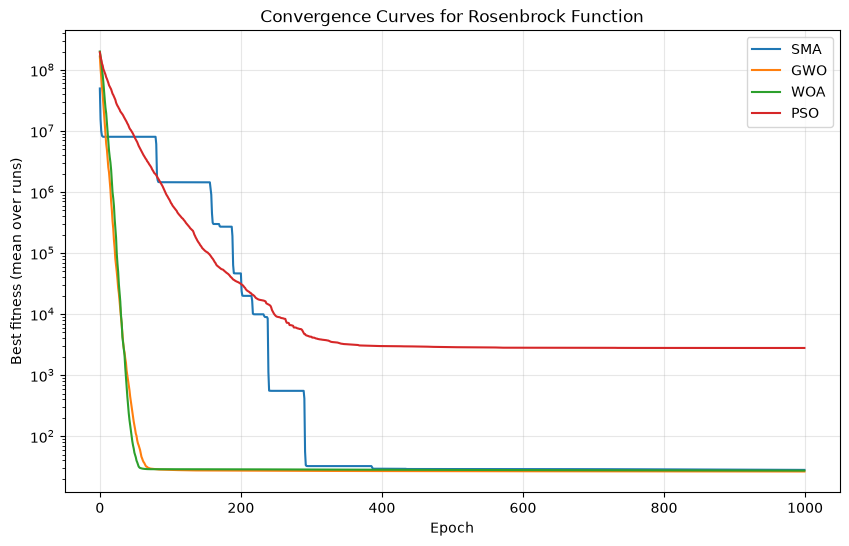

In [21]:
plot_convergence(histories, title="Convergence Curves for Rosenbrock Function", save_path="convergence_curve_rosenbrock.png")


### Apply to machine learning model: hyperparameter tuning

In [22]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def build_model(solution):
    C, gamma = 10**solution[0], 10**solution[1]
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma))

def svm_objective(solution):
    return 1 - cross_val_score(build_model(solution), X_train, y_train, cv=5).mean()

LB, UB = (-3,-4), (3,1)  # Bounds for log10(C) and log10(gamma)

problem = {
    'bounds': FloatVar(lb=LB, ub=UB),
    'minmax': 'min',
    'obj_func': svm_objective,
    'log_to': None
}


In [23]:
#implement random search baseline
def random_search(budget, pop_size, seed):
    rng = np.random.default_rng(seed)
    best_fit, best_sol, history = np.inf, None, []
    for i in range(budget):
        sol = rng.uniform(LB, UB)
        fit = svm_objective(sol)
        if fit < best_fit:
            best_fit, best_sol = fit, sol
        if (i+1) % pop_size == 0:
            history.append(best_fit)
    return best_fit, best_sol, history

In [27]:
def run_ml_experiment(problem, epoch=30,pop_size=20,p_t=0.03,n_runs=30):
    algorithms = {
        'SMA': lambda:SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=p_t),
        'GWO': lambda: GWO.OriginalGWO(epoch=epoch, pop_size=pop_size),
        'WOA': lambda: WOA.OriginalWOA(epoch=epoch, pop_size=pop_size),
        'PSO': lambda: PSO.OriginalPSO(epoch=epoch, pop_size=pop_size)
    }

    names = list(algorithms)+['Random']
    cv_error = {n: [] for n in names}
    test_acc = {n: [] for n in names}
    histories = {n: [] for n in names}

    def record(name, sol, fit, hist):
        cv_error[name].append(fit)
        test_acc[name].append(build_model(sol).fit(X_train, y_train).score(X_test, y_test))
        histories[name].append(hist)

    for run in range(n_runs):
        for name, make_model in algorithms.items():
            model = make_model()
            g_best = model.solve(problem, seed=run)
            record(name, g_best.solution, g_best.target.fitness,
                   model.history.list_global_best_fit)
        sol, fit, hist = random_search(epoch * pop_size, pop_size, seed=run)
        record("Random", sol, fit, hist)
        print(f"finished run {run + 1}/{n_runs}")

    rows = []
    for n in names:
        e = np.array(cv_error[n])
        rows.append({
            "Algorithm": n,
            "AVG CV error": e.mean(),
            "STD": e.std(ddof=1),
            "MED": np.median(e),
            "Mean test acc": np.mean(test_acc[n]),
        })
    table = pd.DataFrame(rows).set_index("Algorithm")
    return table, cv_error, test_acc, histories

# Start tiny to check it works and time it
table, cv_error, test_acc, histories = run_ml_experiment(problem, n_runs=2)
print(table.to_string(float_format=lambda x: f"{x:.4f}"))

IndexError: invalid index to scalar variable.